# Python for Chemists — Day 5
## Specific capacitance from GCD (galvanostatic charge–discharge) curves ⚡🔋

**What you will learn today**
1. Load GCD data from a CSV file
2. Let Python find where the **discharge** starts (no more reading Δt by eye!)
3. Calculate **specific capacitance** (F/g)
4. Correct for the **IR drop** (a mistake reviewers often catch)
5. Repeat for all current densities in a loop → **rate-capability table and plot**

> **Simple idea:** Think of the electrode like a water tank. During discharge, we let water out at a fixed speed (the current). The longer the tank takes to empty (Δt) for the same drop in water level (ΔV), the bigger the tank (the capacitance).

**Formula**

$$C_s = \frac{I \times \Delta t}{m \times \Delta V} \quad\text{or, if current is already per gram:}\quad C_s = \frac{j \times \Delta t}{\Delta V}$$

- $j$ = current density (A/g)
- $\Delta t$ = discharge time (s)
- $\Delta V$ = potential window during discharge (V), **after removing the IR drop**

*Note: `GCD_sample_data.csv` is a sample (simulated) dataset for a pseudocapacitive metal-oxide electrode in a 3-electrode cell, made only for teaching. Replace it with your own data.*

## Step 1 — Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("GCD_sample_data.csv")   # columns: current_density_Ag, time_s, potential_V
print(df.head())
print("\nCurrent densities in file (A/g):", sorted(df["current_density_Ag"].unique()))

   current_density_Ag  time_s  potential_V
0                 0.5   0.000     -0.00064
1                 0.5   1.317      0.00092
2                 0.5   2.634      0.00376
3                 0.5   3.951      0.00627
4                 0.5   5.268      0.00882

Current densities in file (A/g): [np.float64(0.5), np.float64(1.0), np.float64(2.0), np.float64(5.0), np.float64(10.0)]


## Step 2 — Plot one GCD curve (1 A/g)

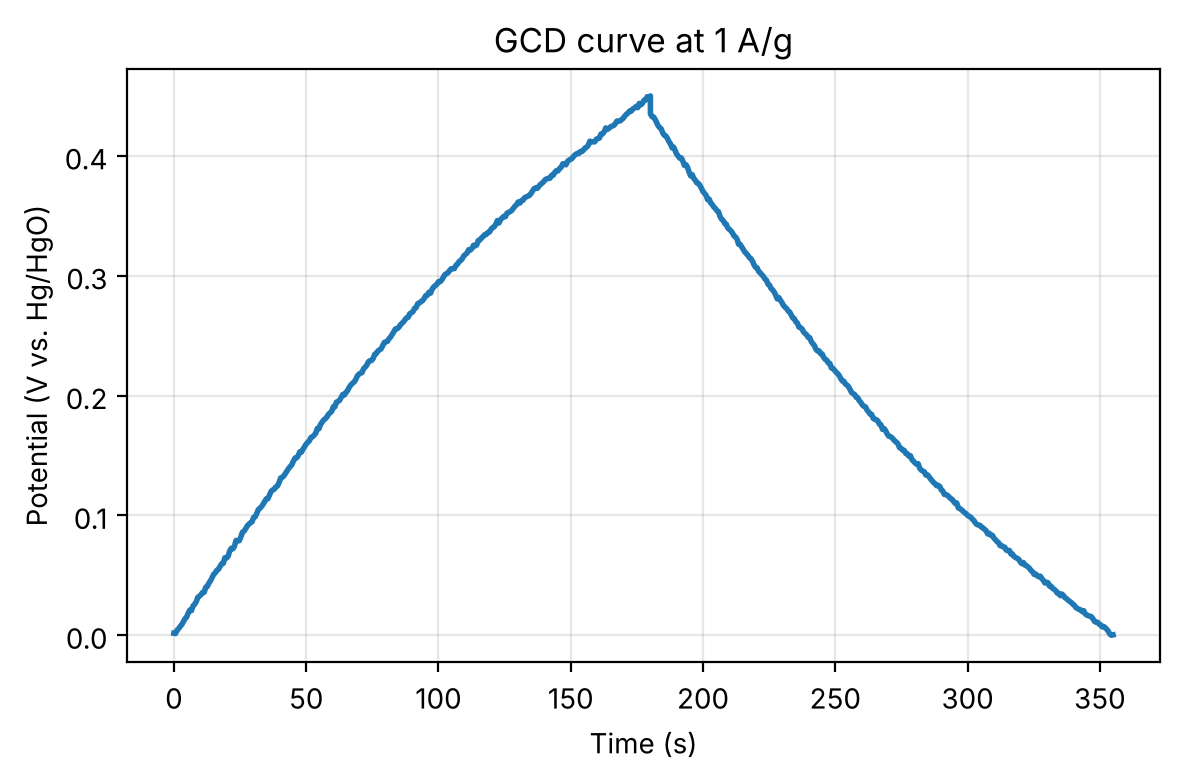

In [2]:
one = df[df["current_density_Ag"] == 1.0].reset_index(drop=True)

plt.figure(figsize=(6, 4))
plt.plot(one["time_s"], one["potential_V"], color="tab:blue", lw=2)
plt.xlabel("Time (s)")
plt.ylabel("Potential (V vs. Hg/HgO)")
plt.title("GCD curve at 1 A/g")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 3 — Find the discharge part automatically

The discharge starts at the **highest voltage** (the top of the triangle).
`idxmax()` finds that point for us, so everything after it is the discharge.

In [3]:
peak = one["potential_V"].idxmax()          # index of the highest voltage
dis = one.loc[peak:].reset_index(drop=True)  # discharge part only

print(f"Discharge starts at t = {one.loc[peak, 'time_s']:.1f} s, V = {one.loc[peak, 'potential_V']:.3f} V")

Discharge starts at t = 180.1 s, V = 0.450 V


## Step 4 — Specific capacitance (simple version, no IR correction)

In [4]:
j = 1.0  # A/g

dt = dis["time_s"].iloc[-1] - dis["time_s"].iloc[0]
dV_raw = dis["potential_V"].iloc[0] - dis["potential_V"].iloc[-1]

Cs_raw = j * dt / dV_raw
print(f"Discharge time Δt = {dt:.1f} s")
print(f"ΔV (full window)  = {dV_raw:.3f} V")
print(f"Specific capacitance (no IR correction) = {Cs_raw:.1f} F/g")

Discharge time Δt = 174.9 s
ΔV (full window)  = 0.450 V
Specific capacitance (no IR correction) = 388.8 F/g


## Step 5 — 💡 Correct for the IR drop

At the very start of discharge, the voltage **drops suddenly** (vertical jump). This is the **IR drop**, caused by the internal resistance of the electrode/electrolyte — it is *not* stored charge.

If you include it in ΔV, you mix resistance into capacitance. The correct ΔV starts **after** the drop.

Here we take the point right after the peak as the "after IR drop" voltage.

In [5]:
V_peak = dis["potential_V"].iloc[0]
V_after_IR = dis["potential_V"].iloc[1]     # first point after the sudden drop
IR_drop = V_peak - V_after_IR

dV_corr = V_after_IR - dis["potential_V"].iloc[-1]
Cs_corr = j * dt / dV_corr

print(f"IR drop = {IR_drop*1000:.1f} mV")
print(f"ΔV (after IR drop) = {dV_corr:.3f} V")
print(f"Specific capacitance (IR-corrected) = {Cs_corr:.1f} F/g")

IR drop = 14.9 mV
ΔV (after IR drop) = 0.435 V
Specific capacitance (IR-corrected) = 402.2 F/g


> **Tip:** With real instrument data, the IR drop may be spread over 2–3 points. Zoom into the first few seconds of discharge and choose the point where the curve stops falling vertically. Always state in your paper whether ΔV is IR-corrected.

## Step 6 — Do it for ALL current densities in one loop (rate capability)

In [6]:
def specific_capacitance(curve, j):
    curve = curve.reset_index(drop=True)
    peak = curve["potential_V"].idxmax()
    dis = curve.loc[peak:].reset_index(drop=True)
    dt = dis["time_s"].iloc[-1] - dis["time_s"].iloc[0]
    ir = dis["potential_V"].iloc[0] - dis["potential_V"].iloc[1]
    dV = dis["potential_V"].iloc[1] - dis["potential_V"].iloc[-1]
    return dt, ir, j * dt / dV

results = []
for j, curve in df.groupby("current_density_Ag"):
    dt, ir, cs = specific_capacitance(curve, j)
    results.append({"j (A/g)": j, "Δt (s)": round(dt, 1),
                    "IR drop (mV)": round(ir * 1000, 1), "Cs (F/g)": round(cs, 1)})

table = pd.DataFrame(results)
table["Retention (%)"] = (table["Cs (F/g)"] / table["Cs (F/g)"].iloc[0] * 100).round(1)
table

,j (A/g),Δt (s),IR drop (mV),Cs (F/g),Retention (%)
0,0.5,382.3,8.4,432.6,100.0
1,1.0,174.9,14.9,402.2,93.0
2,2.0,75.8,29.9,361.3,83.5
3,5.0,22.4,76.5,298.7,69.0
4,10.0,7.4,150.7,247.5,57.2


## Step 7 — Publication-style figure: GCD curves + rate capability

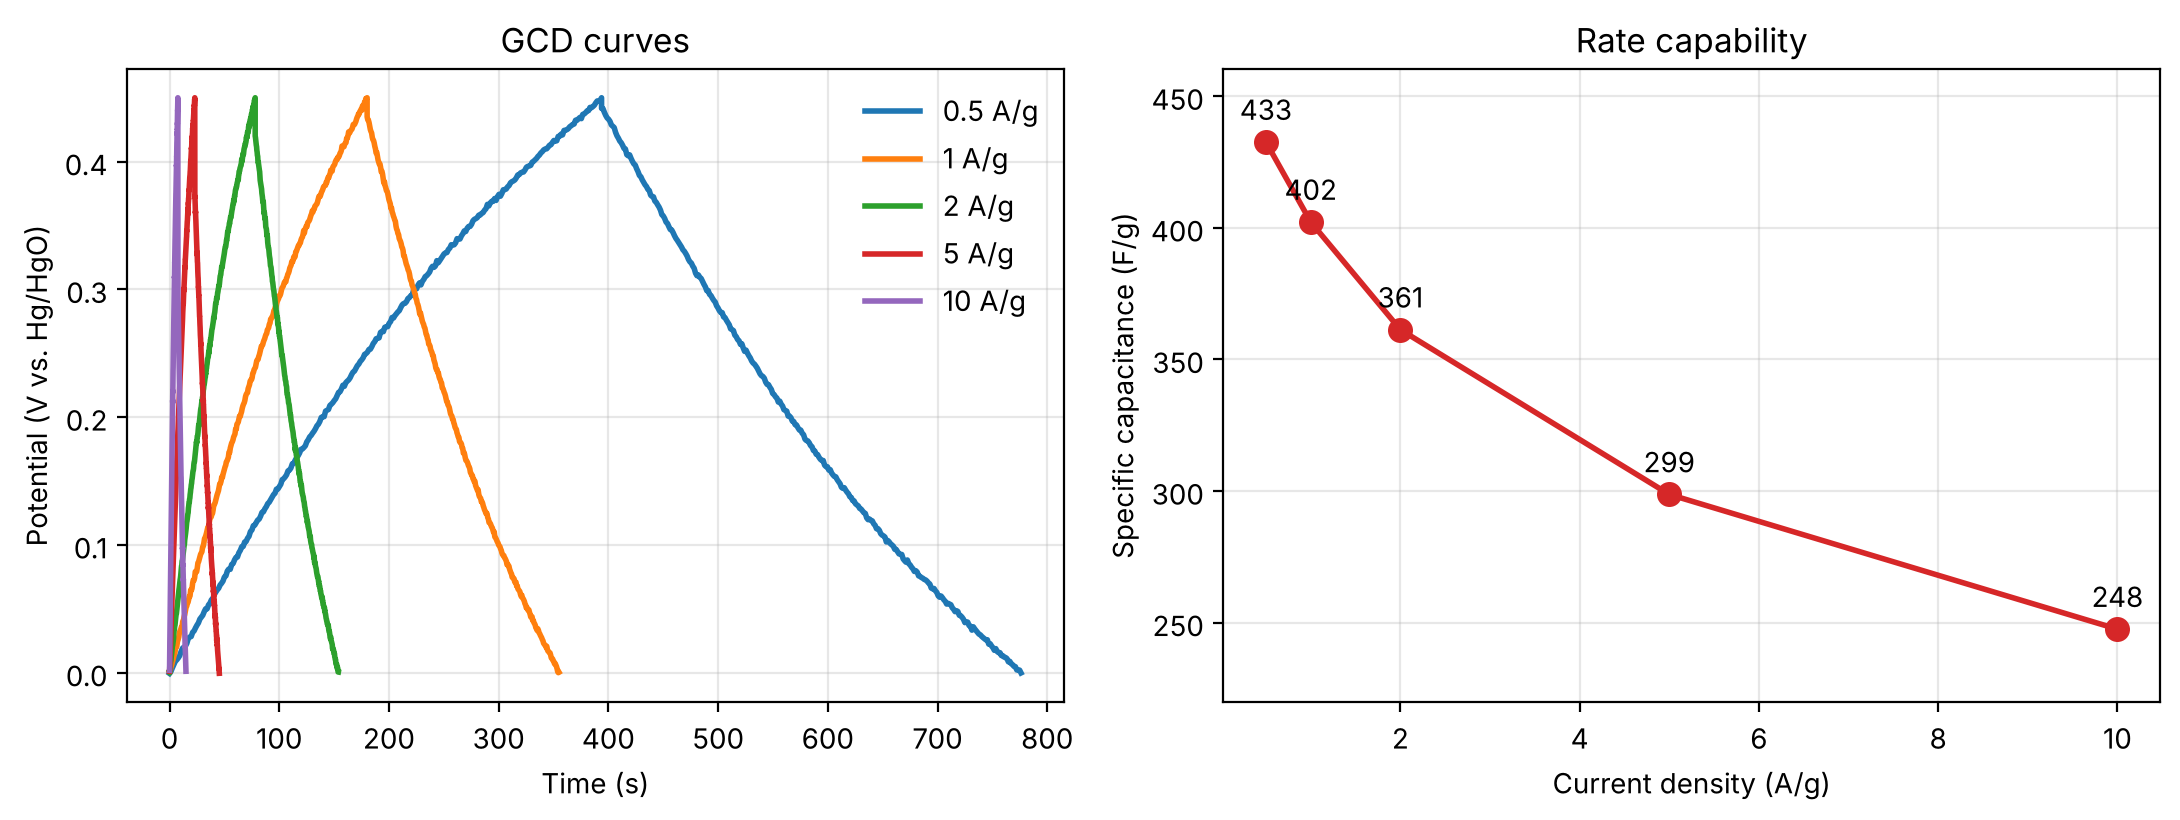

Saved: Day05_GCD_capacitance.png and Day05_capacitance_results.csv


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for j, curve in df.groupby("current_density_Ag"):
    ax1.plot(curve["time_s"], curve["potential_V"], lw=2, label=f"{j:g} A/g")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Potential (V vs. Hg/HgO)")
ax1.set_title("GCD curves")
ax1.legend(frameon=False)
ax1.grid(alpha=0.3)

ax2.plot(table["j (A/g)"], table["Cs (F/g)"], "o-", color="tab:red", lw=2, ms=8)
for x, y in zip(table["j (A/g)"], table["Cs (F/g)"]):
    ax2.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax2.set_xlabel("Current density (A/g)")
ax2.set_ylabel("Specific capacitance (F/g)")
ax2.set_title("Rate capability")
ax2.grid(alpha=0.3)
ax2.margins(y=0.15)

plt.tight_layout()
plt.savefig("Day05_GCD_capacitance.png", dpi=300)
plt.show()

table.to_csv("Day05_capacitance_results.csv", index=False)
print("Saved: Day05_GCD_capacitance.png and Day05_capacitance_results.csv")

## ✅ Summary
- `idxmax()` finds the start of discharge automatically
- $C_s = j\,\Delta t / \Delta V$ with ΔV **after** the IR drop
- One loop gives the full rate-capability table and figure

**Use your own data:** export your GCD file as CSV with columns `current_density_Ag, time_s, potential_V` (or rename the columns in Step 1).

⚠️ This is the **three-electrode, single-electrode** capacitance. For a two-electrode (symmetric) device, the formula changes (multiply by 4 for the single-electrode value, or use the total mass of both electrodes for the device value).

**Next (Day 6):** CV curves or EIS Nyquist plots — tell me in the LinkedIn comments!

*Muhammad Amjad — Python for Chemists series*